
# Homework 2 - Tree Methods

## Calibration of a Balanced Binomial Tree

### Objective

The goal of this homework is to implement a calibration
method for a Balanced Binomial Tree model.

The calibration method finds the up-step size that
matches a given European call option price.

We will test the model using different numbers of
steps, strike prices, and maturities, and visualize
the results using graphs.


In [1]:

import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import brentq

# European Call Option payoff
def european_call_payoff(S, K):
    return max(S - K, 0.0)


# Create the stock price tree
def create_spot_tree(spot, spot_mult_up, spot_mult_down, steps):
    previous_level = [spot]
    tree = [previous_level]

    for _ in range(steps):
        new_level = [s * spot_mult_down for s in previous_level]
        new_level.append(previous_level[-1] * spot_mult_up)

        tree.append(new_level)
        previous_level = new_level

    return tree


# Balanced downward step
def calcBalancedDownStep(spot_mult_up, discount_factor):
    return 2 / discount_factor - spot_mult_up


# Price European Call with a Balanced Binomial Tree
def balanced_call_price(S0, K, r, T, steps, up):

    if steps < 1 or T <= 0:
        raise ValueError("Steps and maturity must be positive")

    dt = T / steps
    discount_factor = np.exp(-r * dt)

    down = calcBalancedDownStep(up, discount_factor)

    growth = 1 / discount_factor
    if not (0 < down < growth < up):
        raise ValueError("Invalid up/down multipliers")

    spot_tree = create_spot_tree(S0, up, down, steps)

    # Payoff at maturity
    values = np.array([
        european_call_payoff(S, K)
        for S in spot_tree[-1]
    ])

    # Backward induction with p_up = p_down = 0.5
    for _ in range(steps):
        values = discount_factor * 0.5 * (
            values[:-1] + values[1:]
        )

    return float(values[0])


In [2]:

# Test the Balanced Binomial Tree

price = balanced_call_price(
    S0=100,
    K=100,
    r=0.05,
    T=1,
    steps=2,
    up=1.20
)

print(f"European Call Price: {price:.4f}")


European Call Price: 11.4507



## Part 2 - Calibration of the Balanced Binomial Tree

The objective is to find the up-step multiplier that
makes the binomial tree price match a given European
call option market price.

I use the Brent root-finding method to minimize
the difference between the model price and the target price.


In [3]:

from scipy.optimize import brentq

def calibrate_up_step(target_price, S0, K, r, T, steps):

    # Calculate the growth factor per step
    growth = np.exp(r * T / steps)

    # Valid bounds for the up multiplier
    lower = growth + 1e-10
    upper = 2 * growth - 1e-10

    # Difference between model and target price
    def pricing_error(up):
        model_price = balanced_call_price(
            S0, K, r, T, steps, up
        )
        return model_price - target_price

    # Check whether calibration is possible
    if pricing_error(lower) * pricing_error(upper) > 0:
        raise ValueError("Target price is outside valid range")

    # Find the calibrated up-step multiplier
    calibrated_up = brentq(
        pricing_error, lower, upper, xtol=1e-12
    )

    return calibrated_up


In [4]:

# Test calibration

target_price = 10.45058357

up_calibrated = calibrate_up_step(
    target_price=target_price,
    S0=100,
    K=100,
    r=0.05,
    T=1,
    steps=1
)

model_price = balanced_call_price(
    S0=100,
    K=100,
    r=0.05,
    T=1,
    steps=1,
    up=up_calibrated
)

print(f"Target Price: {target_price:.6f}")
print(f"Calibrated Up Step: {up_calibrated:.6f}")
print(f"Model Price: {model_price:.6f}")
print(f"Calibration Error: {abs(model_price-target_price):.10f}")


Target Price: 10.450584
Calibrated Up Step: 1.219728
Model Price: 10.450584
Calibration Error: 0.0000000000



## Part 3 - Calibration with Different Numbers of Steps

In this experiment, I calibrate the Balanced Binomial
Tree for the same European call option using different
numbers of time steps.

The discount factor is adjusted for each step to keep
the annual risk-free interest rate constant.

I compare the calibrated up-step multipliers and
check whether the model reproduces the target price.


Steps= 1 | Up=1.219728 | Error=3.55e-15
Steps= 2 | Up=1.175628 | Error=3.55e-15
Steps= 3 | Up=1.125847 | Error=1.78e-15
Steps= 5 | Up=1.096797 | Error=1.64e-11
Steps=10 | Up=1.067825 | Error=1.78e-14
Steps=20 | Up=1.046878 | Error=9.85e-12
Steps=40 | Up=1.032709 | Error=2.01e-13


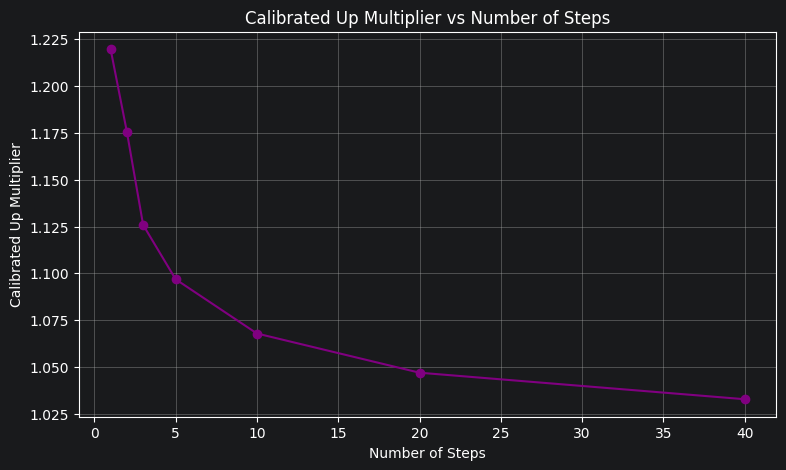

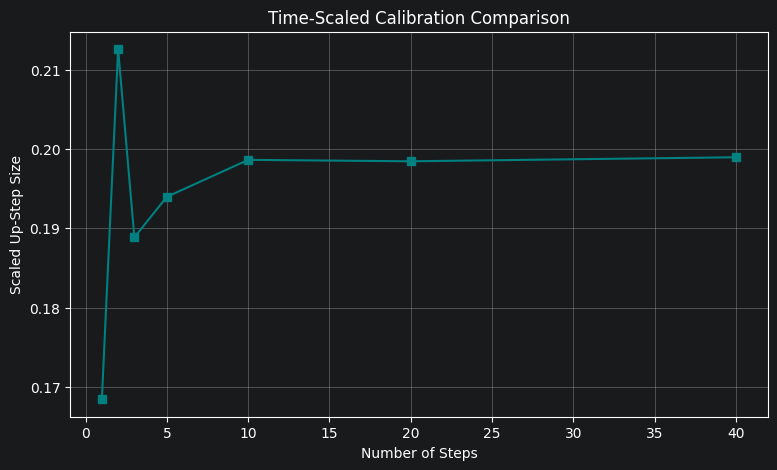

In [5]:

# Experiment: different numbers of steps

steps_list = [1, 2, 3, 5, 10, 20, 40]

up_values = []
scaled_steps = []
errors = []

for n in steps_list:
    up = calibrate_up_step(
        target_price=10.45058357,
        S0=100,
        K=100,
        r=0.05,
        T=1,
        steps=n
    )

    model_price = balanced_call_price(
        S0=100, K=100, r=0.05,
        T=1, steps=n, up=up
    )

    dt = 1 / n
    growth = np.exp(0.05 * dt)

    up_values.append(up)
    scaled_steps.append((up - growth) / np.sqrt(dt))
    errors.append(abs(model_price - 10.45058357))

    print(
        f"Steps={n:2d} | Up={up:.6f} | "
        f"Error={errors[-1]:.2e}"
    )

# Plot the calibrated up multipliers
plt.figure(figsize=(9, 5))
plt.plot(steps_list, up_values, "o-", color="purple")
plt.xlabel("Number of Steps")
plt.ylabel("Calibrated Up Multiplier")
plt.title("Calibrated Up Multiplier vs Number of Steps")
plt.grid(True)
plt.show()

# Plot the step sizes scaled by the time increment
plt.figure(figsize=(9, 5))
plt.plot(steps_list, scaled_steps, "s-", color="teal")
plt.xlabel("Number of Steps")
plt.ylabel("Scaled Up-Step Size")
plt.title("Time-Scaled Calibration Comparison")
plt.grid(True)
plt.show()



## Part 4 - Calibration for Different Strike Prices

In this experiment, I calibrate a one-step Balanced
Binomial Tree for European call options with
different strike prices.

The risk-free interest rate and volatility remain
constant.

I use Black-Scholes-Merton prices as target prices
and compare the calibrated up-step multipliers.


Strike=90 | Target=16.6994 | Up=1.251113
Strike=95 | Target=13.3465 | Up=1.230615
Strike=100 | Target=10.4506 | Up=1.219728
Strike=105 | Target=8.0214 | Up=1.218652
Strike=110 | Target=6.0401 | Up=1.226995


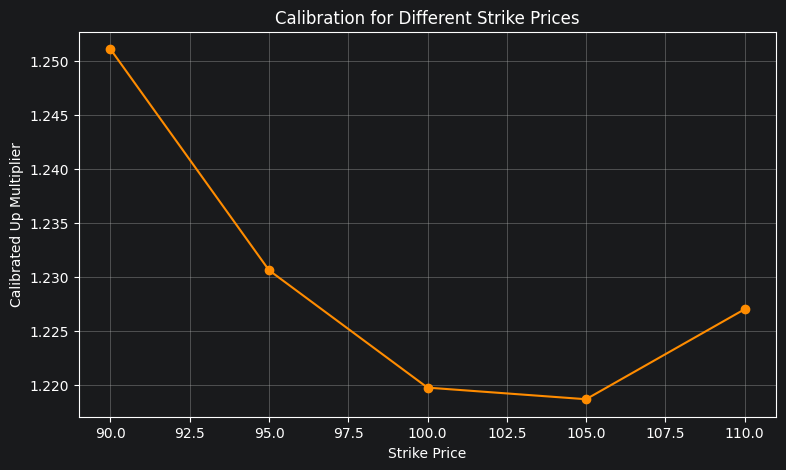

In [6]:

from scipy.stats import norm

# Fixed model parameters
S0 = 100
r = 0.05
T = 1
sigma = 0.20
steps = 1

# Different strike prices
strikes = [90, 95, 100, 105, 110]

calibrated_ups = []
target_prices = []

for K in strikes:

    # Black-Scholes-Merton target price
    d1 = (np.log(S0 / K) + (r + 0.5 * sigma**2) * T) / (
        sigma * np.sqrt(T)
    )
    d2 = d1 - sigma * np.sqrt(T)

    target = S0 * norm.cdf(d1) - K * np.exp(-r*T) * norm.cdf(d2)

    # Calibrate the tree
    up = calibrate_up_step(target, S0, K, r, T, steps)

    calibrated_ups.append(up)
    target_prices.append(target)

    print(f"Strike={K} | Target={target:.4f} | Up={up:.6f}")

# Plot calibration results
plt.figure(figsize=(9, 5))
plt.plot(strikes, calibrated_ups, "o-", color="darkorange")

plt.xlabel("Strike Price")
plt.ylabel("Calibrated Up Multiplier")
plt.title("Calibration for Different Strike Prices")
plt.grid(True)
plt.show()



## Part 5 - Calibration for Different Expiries

In this experiment, I calibrate a one-step Balanced
Binomial Tree for European call options with different
times to maturity.

The strike price, stock price, volatility and annual
risk-free interest rate remain constant.

I use Black-Scholes-Merton prices as target prices
and compare the calibrated up-step multipliers
for different maturities.


T=0.25 years | Target=4.6150 | Up=1.093461 | Error=5.33e-15
T=0.50 years | Target=6.8887 | Up=1.141262 | Error=2.66e-15
T=1.00 years | Target=10.4506 | Up=1.219728 | Error=0.00e+00
T=1.50 years | Target=13.4429 | Up=1.289798 | Error=7.11e-15
T=2.00 years | Target=16.1268 | Up=1.356457 | Error=0.00e+00


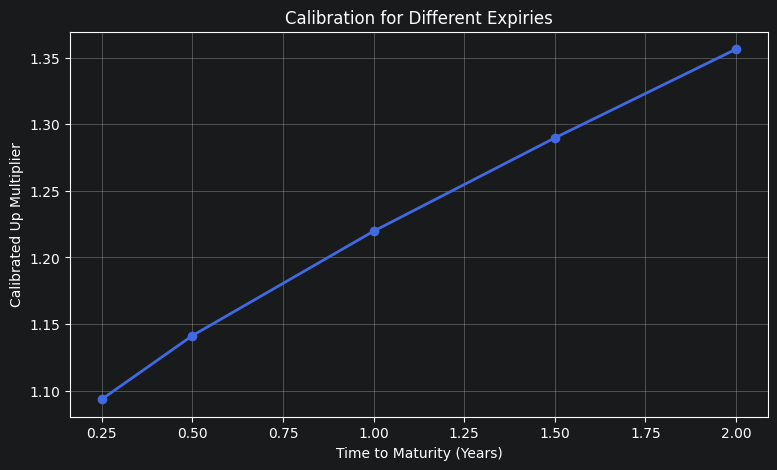

In [7]:

# Part 5 - Calibration for Different Expiries

S0 = 100
K = 100
r = 0.05
sigma = 0.20
steps = 1

# Different maturities in years
maturities = [0.25, 0.5, 1, 1.5, 2]

expiry_ups = []
expiry_errors = []

for T in maturities:

    # Black-Scholes-Merton target price
    d1 = (np.log(S0 / K) + (r + 0.5 * sigma**2) * T) / (
        sigma * np.sqrt(T)
    )
    d2 = d1 - sigma * np.sqrt(T)

    target = S0 * norm.cdf(d1) - K * np.exp(-r*T) * norm.cdf(d2)

    # Calibrate the Balanced Binomial Tree
    up = calibrate_up_step(target, S0, K, r, T, steps)

    model_price = balanced_call_price(
        S0, K, r, T, steps, up
    )

    expiry_ups.append(up)
    expiry_errors.append(abs(model_price - target))

    print(
        f"T={T:.2f} years | Target={target:.4f} | "
        f"Up={up:.6f} | Error={expiry_errors[-1]:.2e}"
    )

# Plot the results
plt.figure(figsize=(9, 5))
plt.plot(
    maturities,
    expiry_ups,
    "o-",
    color="royalblue",
    linewidth=2
)

plt.xlabel("Time to Maturity (Years)")
plt.ylabel("Calibrated Up Multiplier")
plt.title("Calibration for Different Expiries")
plt.grid(True)
plt.show()



## Part 6 - Calibrated Call Prices for Different Maturities

This experiment compares European call option prices
for different strike prices and maturities.

For each contract, I calibrate the Balanced Binomial
Tree to match its Black-Scholes-Merton target price.

The graph illustrates the effect of strike price
and maturity on the calibrated call option prices.


T=0.5: Max Error = 7.11e-15
T=1.0: Max Error = 1.07e-14
T=2.0: Max Error = 7.11e-15


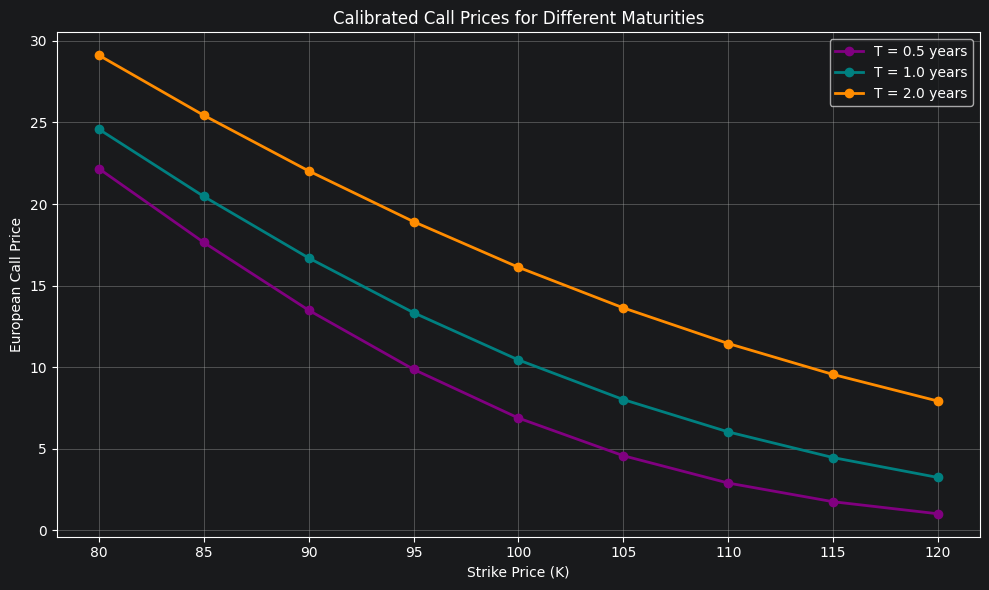

In [8]:

# Part 6 - Calibrated Call Prices

from scipy.stats import norm

S0 = 100
r = 0.05
sigma = 0.20
steps = 1

strikes = np.arange(80, 125, 5)
maturities = [0.5, 1.0, 2.0]

colors = ["purple", "teal", "darkorange"]

plt.figure(figsize=(10, 6))

for i, T in enumerate(maturities):
    calibrated_prices = []
    errors = []

    for K in strikes:

        # BSM target price
        d1 = (np.log(S0 / K) +
              (r + 0.5 * sigma**2) * T) / (
                  sigma * np.sqrt(T)
              )
        d2 = d1 - sigma * np.sqrt(T)

        target = (
            S0 * norm.cdf(d1)
            - K * np.exp(-r * T) * norm.cdf(d2)
        )

        # Calibrate the up-step multiplier
        up = calibrate_up_step(
            target, S0, K, r, T, steps
        )

        # Calculate fitted tree price
        fitted_price = balanced_call_price(
            S0, K, r, T, steps, up
        )

        calibrated_prices.append(fitted_price)
        errors.append(abs(fitted_price - target))

    plt.plot(
        strikes,
        calibrated_prices,
        marker="o",
        linewidth=2,
        color=colors[i],
        label=f"T = {T} years"
    )

    print(f"T={T}: Max Error = {max(errors):.2e}")

plt.title("Calibrated Call Prices for Different Maturities")
plt.xlabel("Strike Price (K)")
plt.ylabel("European Call Price")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()



## Conclusion

In this homework, I implemented a calibration method
for a Balanced Binomial Tree with equal risk-neutral
up and down probabilities of 0.5.

The calibration successfully matched the target
Black-Scholes-Merton European call prices for the
tested parameters, with very small numerical errors.

The experiments showed that:

- The calibrated up multiplier approaches 1 as the
  number of time steps increases.
- The time-scaled step size becomes more stable for
  larger numbers of steps.
- Different strike prices require different calibrated
  up multipliers.
- Longer maturities resulted in higher calibrated up
  multipliers in the tested one-step model.

Overall, the results illustrate how the Balanced
Binomial Tree can be calibrated to given option prices.
